# 01 — Exploration des données (EDA)
**Projet :** prédiction des impayés télécom (`default_risk`) — CC1 MLOps, EADL5 / JA  
**Auteurs :** MBONGO BOLLO Jarle Wulfrid · DONGMO WOZE Junior

Objectifs : comprendre le jeu *Telecom Credit Scoring Data (Nigeria)*, vérifier la qualité des données, choisir les variables et repérer les risques de fuite (*data leakage*).

> Exécuter d'abord `python -m impayes.data.download` pour obtenir `data/raw/telecom_credit_scoring_data.parquet`. Le fichier `data/raw/SOURCE.json` indique si ce sont les vraies données ou la réplique synthétique hors-ligne.

In [1]:
import json, sys
from pathlib import Path
import pandas as pd, numpy as np, matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
df = pd.read_parquet(ROOT / "data/raw/telecom_credit_scoring_data.parquet")
print(json.loads((ROOT / "data/raw/SOURCE.json").read_text()))
print(df.shape)
df.head()

{'source': 'synthetic_replica', 'detail': 'impayes.data.synthetic.generate', 'rows': 200000, 'retrieved_at': '2026-10-28T15:55:03.509729+00:00'}
(200000, 15)


,customer_id,phone_number,operator,assessment_date,credit_score,credit_rating,tenure_months,avg_monthly_spend_ngn,recharge_frequency_per_month,payment_consistency_score,late_payment_count,account_type,loan_eligibility,max_loan_amount_ngn,default_risk
0,CUST9877441,+2348152502055,Glo,2025-09-30,623,fair,26,18347.51,13,0.15,1,prepaid,False,0.00,medium
1,CUST2975752,+2347013452312,Airtel,2025-09-30,645,fair,48,2993.11,12,0.12,0,prepaid,False,0.00,high
2,CUST9345687,+2348156570267,Glo,2025-09-30,905,excellent,51,48717.52,12,0.48,1,postpaid,True,71458.82,low
3,CUST2682576,+2348123093325,Airtel,2025-09-30,1000,excellent,107,28793.94,24,0.58,0,prepaid,True,73392.72,low
4,CUST2078204,+2349062145879,MTN,2025-09-30,548,fair,8,38950.21,2,0.09,3,prepaid,False,0.00,high


## 1. Schéma, types et valeurs manquantes

In [2]:
pd.DataFrame({"type": df.dtypes.astype(str), "manquants": df.isna().sum(), "uniques": df.nunique()})

,type,manquants,uniques
customer_id,str,0,200000
phone_number,str,0,199911
operator,str,0,4
assessment_date,datetime64[us],0,1
credit_score,int64,0,701
credit_rating,str,0,4
tenure_months,int64,0,120
avg_monthly_spend_ngn,float64,0,196055
recharge_frequency_per_month,int64,0,30
payment_consistency_score,float64,0,101


In [3]:
df.describe().T.round(2)

,count,mean,min,25%,50%,75%,max,std
assessment_date,200000,2025-09-30 00:00:00,2025-09-30 00:00:00,2025-09-30 00:00:00,2025-09-30 00:00:00,2025-09-30 00:00:00,2025-09-30 00:00:00,NaN
credit_score,200000.0,761.896395,300.0,637.0,779.0,915.0,1000.0,182.063939
tenure_months,200000.0,60.364235,1.0,30.0,60.0,90.0,120.0,34.637792
avg_monthly_spend_ngn,200000.0,25290.482804,500.24,12956.4025,25298.52,37647.9525,49999.91,14264.011788
recharge_frequency_per_month,200000.0,15.513915,1.0,8.0,16.0,23.0,30.0,8.661906
payment_consistency_score,200000.0,0.50035,0.0,0.25,0.5,0.75,1.0,0.288802
late_payment_count,200000.0,1.815075,0.0,0.0,1.0,2.0,10.0,2.23802
max_loan_amount_ngn,200000.0,39870.430062,0.0,0.0,36841.005,65662.81,139721.61,35673.059418


## 2. Variable cible `default_risk`
Trois classes déséquilibrées : on utilise `class_weight='balanced'`, un split **stratifié** et le **F1-macro** comme métrique principale (l'accuracy serait trompeuse).

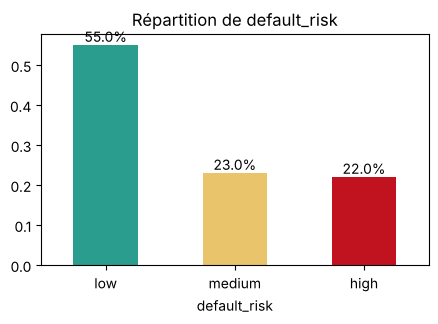

default_risk
low       0.55
medium    0.23
high      0.22
Name: proportion, dtype: float64

In [4]:
share = df["default_risk"].value_counts(normalize=True).reindex(["low","medium","high"])
ax = share.plot.bar(color=["#2A9D8F","#E9C46A","#C1121F"], figsize=(5,3), rot=0, title="Répartition de default_risk")
ax.bar_label(ax.containers[0], fmt="{:.1%}"); plt.show(); share.round(3)

## 3. Variables comportementales vs risque

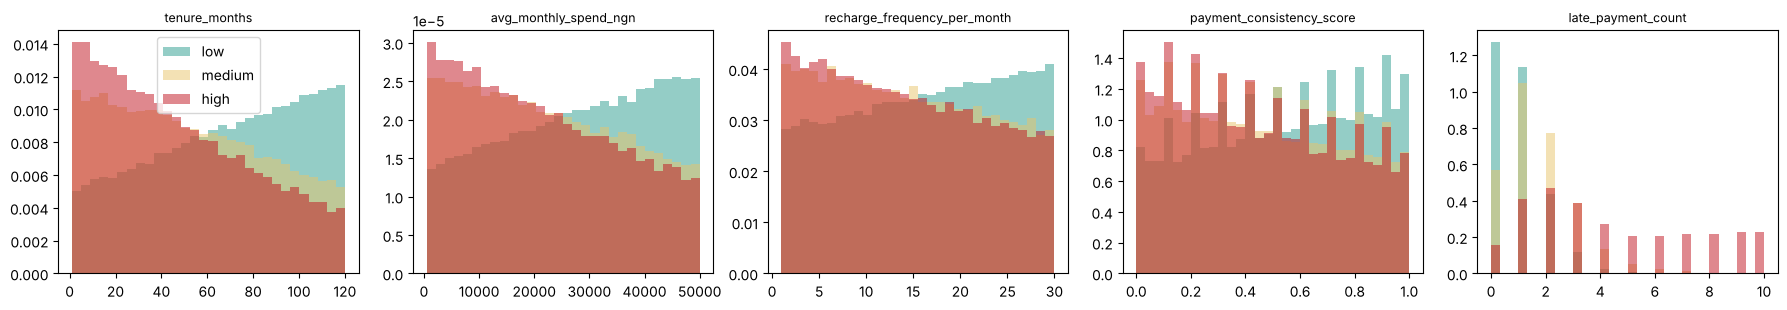

,tenure_months,avg_monthly_spend_ngn,recharge_frequency_per_month,payment_consistency_score,late_payment_count
default_risk,,,,,
low,68.47,27808.73,16.43,0.54,0.84
medium,53.28,22744.40,14.55,0.46,1.60
high,47.50,21656.69,14.25,0.45,4.48


In [5]:
num = ["tenure_months","avg_monthly_spend_ngn","recharge_frequency_per_month","payment_consistency_score","late_payment_count"]
fig, axes = plt.subplots(1, 5, figsize=(18,3.2))
for ax, c in zip(axes, num):
    for cls, col in [("low","#2A9D8F"),("medium","#E9C46A"),("high","#C1121F")]:
        ax.hist(df.loc[df.default_risk==cls, c], bins=30, alpha=.5, density=True, color=col, label=cls)
    ax.set_title(c, fontsize=9)
axes[0].legend(); plt.tight_layout(); plt.show()
df.groupby("default_risk")[num].mean().reindex(["low","medium","high"]).round(2)

## 4. Variables catégorielles

In [6]:
pd.crosstab(df.operator, df.default_risk, normalize="index").round(3)

default_risk,high,low,medium
operator,,,
9mobile,0.221,0.549,0.230
Airtel,0.219,0.553,0.228
Glo,0.221,0.546,0.233
MTN,0.220,0.550,0.230


In [7]:
pd.crosstab(df.account_type, df.default_risk, normalize="index").round(3)

default_risk,high,low,medium
account_type,,,
postpaid,0.256,0.493,0.250
prepaid,0.214,0.560,0.226


## 5. Risque de fuite (*leakage*) et données personnelles
- `credit_score`, `credit_rating`, `loan_eligibility`, `max_loan_amount_ngn` sont **produits par un autre système de scoring** (calculés au même moment que la cible). Les utiliser reviendrait à apprendre la règle d'un autre modèle et à créer une dépendance circulaire : **exclus**.
- `customer_id`, `phone_number` : identifiants / données personnelles → **exclus** (NDPR / RGPD).
- `assessment_date` est constante → aucune information.

In [8]:
print("assessment_date uniques :", df.assessment_date.nunique())
pd.crosstab(df.credit_rating, df.default_risk, normalize="index").round(3)

assessment_date uniques : 1


default_risk,high,low,medium
credit_rating,,,
excellent,0.057,0.779,0.165
fair,0.397,0.281,0.322
good,0.194,0.498,0.308
poor,0.766,0.076,0.158


In [9]:
# Règle déterministe observée : la notation découle mécaniquement du score
df.groupby("credit_rating").credit_score.agg(["min","max"]).sort_values("min")

,min,max
credit_rating,,
poor,300,499
fair,500,649
good,650,799
excellent,800,1000


## 6. Corrélations entre variables retenues

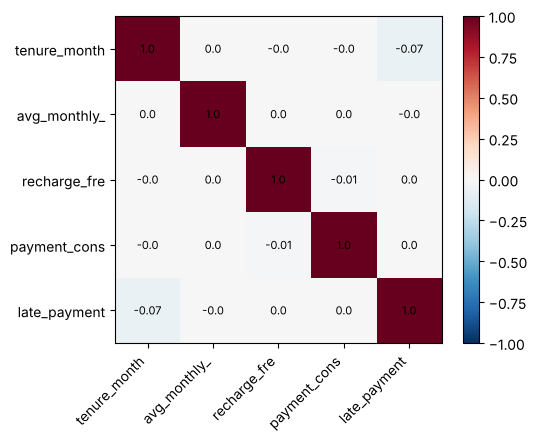

In [10]:
corr = df[num].corr().round(2)
plt.figure(figsize=(5.5,4.5)); plt.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
plt.xticks(range(5), [c[:12] for c in num], rotation=45, ha="right"); plt.yticks(range(5), [c[:12] for c in num])
for i in range(5):
    for j in range(5): plt.text(j, i, corr.iloc[i,j], ha="center", va="center", fontsize=8)
plt.colorbar(); plt.tight_layout(); plt.show()

## 7. Référence naïve
Un modèle qui prédit toujours la classe majoritaire fixe le plancher que tout modèle doit battre largement (test `test_beats_naive_baseline`).

In [11]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score
y = df["default_risk"]
dummy = DummyClassifier(strategy="most_frequent").fit(df[num], y)
print("F1-macro baseline :", round(f1_score(y, dummy.predict(df[num]), average="macro"), 3))

F1-macro baseline : 0.237


## Conclusions
1. Pas de valeurs manquantes ; domaines et plages conformes au *data contract* (`impayes.data.validate`).
2. Cible à 3 classes déséquilibrées → F1-macro, rappel de la classe `high`, pondération des classes.
3. `late_payment_count` est le signal le plus discriminant, suivi de l'ancienneté et des dépenses.
4. Variables retenues : 5 numériques + `operator`, `account_type` + 4 variables dérivées (`spend_per_recharge`, `late_rate`, `log_spend`, `is_new_customer`).
5. Exclusion des scores aval (fuite) et des identifiants (vie privée).